# Hospital scene graphs (Isaac Sim Jackal runs) vs GREP's n60 training graphs (2026-11-01)

Analysis of `../data/hospital_graphs/` — the graphs Arjun's simulated robot hands to GREP
(`hospital_v3`, `hospital_v4`, the 60-task `hospital_v4_length_sweep`, and its
`_neutral` renaming) — against the graphs GREP was trained and evaluated on: the
n60_v3 corpus (`../data/eval/e17_n60_analysis/dataset/`, local copy of
`data/n_60_vllm_v3` on betty: populated training graphs + the 7 frozen test graphs
`data_gen_052–058`) and the v2c route-hop audit (`../data/eval/e21_v2c_analysis/corpus_audit.json`).

Goal: state, in numbers, how the robot graphs differ from the training distribution, so the
next corpus generator can be matched to them. Figures are saved to `../docs/hospital_graphs_*.png`.

Robot-side results quoted here come from the export's README (Arjun's runs); nothing in
this notebook re-runs a model.

In [1]:
import glob, json, os, re
from collections import Counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

HOSP = "../data/hospital_graphs"
N60 = "../data/eval/e17_n60_analysis/dataset"
AUDIT = "../data/eval/e21_v2c_analysis/corpus_audit.json"
FIGS = "../docs"
plt.rcParams.update({"figure.dpi": 120, "font.size": 9})


def load_graph(path):
    d = json.load(open(path))
    g = d["graph"]
    G = nx.Graph()
    G.add_nodes_from(r["name"] for r in g["regions"])
    G.add_edges_from(map(tuple, g["region_connections"]))
    return d, G


def region_type(name):
    # strip trailing _<k>; hospital v4 also carries a zone prefix (inner_west_hall_3 -> hall)
    base = re.sub(r"_\d+$", "", name)
    return base


hosp = {k: load_graph(f"{HOSP}/{k}.json") for k in
        ["hospital_v3", "hospital_v4", "hospital_v4_length_sweep", "hospital_v4_length_sweep_neutral"]}
meta = {k: json.load(open(f"{HOSP}/{k}.sim_meta.json")) for k in hosp}
n60_test = {os.path.basename(p)[:-5]: load_graph(p) for p in sorted(glob.glob(f"{N60}/split/test_graphs/*.json"))}
n60_pop = {os.path.basename(p)[:-5]: load_graph(p) for p in sorted(glob.glob(f"{N60}/populated_graphs/data_gen_*.json"))}
n60_train = {k: v for k, v in n60_pop.items() if k not in n60_test}
print(f"hospital sets: {list(hosp)}")
print(f"n60_v3: {len(n60_pop)} populated graphs, {len(n60_test)} frozen test graphs, {len(n60_train)} train graphs")

hospital sets: ['hospital_v3', 'hospital_v4', 'hospital_v4_length_sweep', 'hospital_v4_length_sweep_neutral']
n60_v3: 59 populated graphs, 7 frozen test graphs, 52 train graphs


## 1. Size and connectivity

One row per graph (hospital) or mean ± sd over graphs (n60). `cycles` is the cyclomatic
number `edges − regions + 1`; `bridge frac` is the fraction of region edges whose removal
disconnects the graph (1.0 = a tree); `articulation` counts regions whose removal
disconnects the graph.

In [2]:
def graph_stats(d, G):
    g = d["graph"]
    degs = [deg for _, deg in G.degree()]
    return dict(
        regions=G.number_of_nodes(), objects=len(g["objects"]), region_edges=G.number_of_edges(),
        mean_deg=np.mean(degs), max_deg=max(degs), deg1_frac=np.mean(np.array(degs) == 1),
        cycles=G.number_of_edges() - G.number_of_nodes() + 1,
        bridge_frac=len(list(nx.bridges(G))) / G.number_of_edges(),
        articulation=len(list(nx.articulation_points(G))),
        diameter=nx.diameter(G), radius=nx.radius(G),
        aspl=nx.average_shortest_path_length(G),
        clustering=nx.average_clustering(G),
    )


rows = {k: graph_stats(*hosp[k]) for k in ["hospital_v3", "hospital_v4"]}
n60_df = pd.DataFrame([graph_stats(*v) for v in n60_pop.values()], index=list(n60_pop))
test_df = n60_df.loc[list(n60_test)]
summary = pd.DataFrame(rows).T
summary.loc["n60_v3 test (7) mean"] = test_df.mean()
summary.loc["n60_v3 all (%d) mean" % len(n60_df)] = n60_df.mean()
summary.loc["n60_v3 all sd"] = n60_df.std()
pd.set_option("display.width", 200)
summary.round(2)

,regions,objects,region_edges,mean_deg,max_deg,deg1_frac,cycles,bridge_frac,articulation,diameter,radius,aspl,clustering
hospital_v3,17.0,22.00,17.00,2.00,4.00,0.29,1.00,0.35,5.00,8.00,5.0,3.65,0.00
hospital_v4,37.0,14.00,40.00,2.16,4.00,0.24,4.00,0.72,25.00,20.00,10.0,8.36,0.05
n60_v3 test (7) mean,48.0,14.71,151.86,6.33,11.00,0.00,104.86,0.00,0.00,4.29,3.0,2.40,0.32
n60_v3 all (59) mean,48.0,15.27,150.05,6.25,10.61,0.00,103.05,0.00,0.07,4.49,3.0,2.42,0.32
n60_v3 all sd,0.0,4.20,8.95,0.37,1.05,0.01,8.95,0.00,0.25,0.54,0.0,0.10,0.04


## 2. Degree distribution

Training regions have ~6 neighbours; the hospital regions have ~2 (corridor chains with
dead ends). The degree-1 fraction (dead ends) is the clearest single discriminator.

n60_v3 degree mean 6.25, dead-ends 0.1%;  v4 mean 2.16, dead-ends 24.3%;  v3 mean 2.00, dead-ends 29.4%


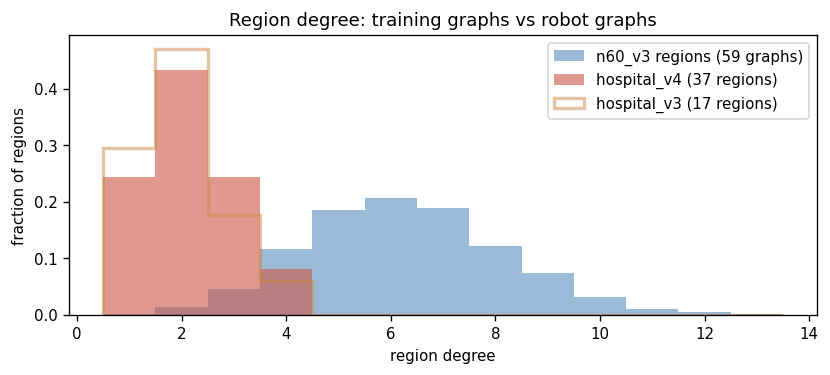

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
deg_n60 = np.concatenate([[d for _, d in G.degree()] for _, G in n60_pop.values()])
deg_v4 = [d for _, d in hosp["hospital_v4"][1].degree()]
deg_v3 = [d for _, d in hosp["hospital_v3"][1].degree()]
bins = np.arange(0.5, max(deg_n60.max(), 8) + 1.5)
ax.hist(deg_n60, bins=bins, density=True, alpha=0.45, color="#2266aa", label=f"n60_v3 regions ({len(n60_pop)} graphs)")
ax.hist(deg_v4, bins=bins, density=True, alpha=0.6, color="#cc5544", label="hospital_v4 (37 regions)")
ax.hist(deg_v3, bins=bins, density=True, alpha=0.5, color="#cc8844", histtype="step", lw=2, label="hospital_v3 (17 regions)")
ax.set_xlabel("region degree"); ax.set_ylabel("fraction of regions"); ax.legend()
ax.set_title("Region degree: training graphs vs robot graphs")
fig.tight_layout(); fig.savefig(f"{FIGS}/hospital_graphs_degree.png")
print(f"n60_v3 degree mean {deg_n60.mean():.2f}, dead-ends {np.mean(deg_n60 == 1):.1%};  "
      f"v4 mean {np.mean(deg_v4):.2f}, dead-ends {np.mean(np.array(deg_v4) == 1):.1%};  "
      f"v3 mean {np.mean(deg_v3):.2f}, dead-ends {np.mean(np.array(deg_v3) == 1):.1%}")

## 3. Shortest-path length between region pairs

The hop distance a *random* (start, goal) pair implies. On n60 graphs almost every pair is
within 3 hops; on hospital_v4 the mass sits at 5–10 hops and reaches 20. Overlaid: the
hop histogram of the v2c training routes (what the model actually practised) and the
hospital_v4 sweep tasks (5 per length, 1–12).

n60_v3 pairs : median 2, 90% 3, max 6, >=6 hops 0.0%
v2c routes   : median 4, 90% 5, max 7, >=6 hops 1.1%
v4 pairs     : median 8, 90% 16, max 20, >=6 hops 63.8%
v3 pairs     : median 4, 90% 6, max 8, >=6 hops 15.4%
v4 sweep     : median 6, 90% 11, max 12, >=6 hops 58.3%


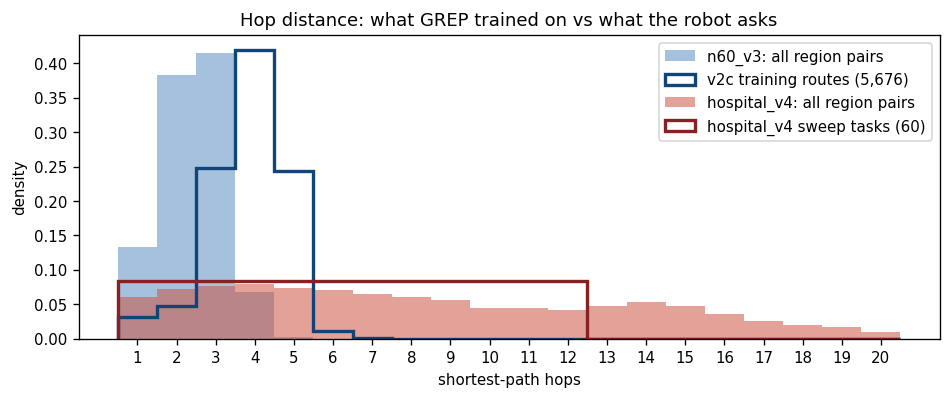

In [4]:
def pair_hops(G):
    return np.array([h for u, dd in nx.all_pairs_shortest_path_length(G) for v, h in dd.items() if v > u])


ph_v4 = pair_hops(hosp["hospital_v4"][1])
ph_v3 = pair_hops(hosp["hospital_v3"][1])
ph_n60 = np.concatenate([pair_hops(G) for _, G in n60_pop.values()])
audit = json.load(open(AUDIT))
v2c_hist = {int(k): v for k, v in audit["v2c_r2 (n_60_oracle_v2c_r2)"]["hop_hist"].items()}
v2c_hops = np.repeat(list(v2c_hist), list(v2c_hist.values()))
sweep_hops = np.array([t["hops"] for t in meta["hospital_v4_length_sweep"]["tasks"]])

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(0.5, 21.5)
ax.hist(ph_n60, bins=bins, density=True, alpha=0.4, color="#2266aa", label="n60_v3: all region pairs")
ax.hist(v2c_hops, bins=bins, density=True, histtype="step", lw=2, color="#114477", label="v2c training routes (5,676)")
ax.hist(ph_v4, bins=bins, density=True, alpha=0.55, color="#cc5544", label="hospital_v4: all region pairs")
ax.hist(sweep_hops, bins=bins, density=True, histtype="step", lw=2, color="#882222", label="hospital_v4 sweep tasks (60)")
ax.set_xlabel("shortest-path hops"); ax.set_ylabel("density"); ax.set_xticks(range(1, 21)); ax.legend()
ax.set_title("Hop distance: what GREP trained on vs what the robot asks")
fig.tight_layout(); fig.savefig(f"{FIGS}/hospital_graphs_hops.png")

def q(a): return f"median {np.median(a):.0f}, 90% {np.percentile(a, 90):.0f}, max {a.max()}, >=6 hops {np.mean(a >= 6):.1%}"
print("n60_v3 pairs :", q(ph_n60)); print("v2c routes   :", q(v2c_hops))
print("v4 pairs     :", q(ph_v4)); print("v3 pairs     :", q(ph_v3)); print("v4 sweep     :", q(sweep_hops))

## 4. Tasks: route length, phrasing, constraints

Hospital tasks from `*.sim_meta.json` (`init_node`, `goal_node`, `via_node`, `avoid_node`,
`hops`); n60 test tasks from the 7 frozen graphs (`init_node`, acceptance criterion,
`answer` regex). Hops for n60 are BFS start→goal on the region graph (waypoint detours
not added, same convention as the README). "starting area" = the indexical start phrasing
the e21 fix targeted; v2c trains it at 36%.

In [5]:
SA_RE = re.compile(r"starting (area|location|point|position)|current (location|position)", re.I)

def task_rows_hosp(k):
    d, G = hosp[k]
    out = []
    for t, m in zip(d["tasks"], meta[k]["tasks"]):
        hops = m["hops"] if m["hops"] is not None else nx.shortest_path_length(G, m["init_node"], m["goal_node"])
        out.append(dict(set=k, hops=hops, starting_area=bool(SA_RE.search(t["task"])), via=m["via_node"] is not None,
                        avoid=m["avoid_node"] is not None, object_goal=m["goal_object"] is not None,
                        start_is_robot_loc=m["init_node"] == d["graph"]["robot_location"]))
    return out

def task_rows_n60():
    out = []
    for name, (d, G) in n60_test.items():
        obj_region = dict(map(tuple, d["graph"]["object_connections"]))
        for t in d["tasks"]:
            ac = t.get("acceptance_criterion", "")
            # goal = last node named in the answer regex
            nodes = re.findall(r"\\b([a-z0-9_]+)\\b", t["answer"])
            nodes = [n for n in nodes if n in G or n in obj_region]
            goal = nodes[-1] if nodes else None
            goal_r = obj_region.get(goal, goal)
            hops = nx.shortest_path_length(G, t["init_node"], goal_r) if goal_r in G and t["init_node"] in G else np.nan
            out.append(dict(set="n60_v3 test", hops=hops, starting_area=bool(SA_RE.search(t["task"])),
                            via=("passing through" in t["task"].lower()) or ("via" in t["task"].lower()),
                            avoid=("without" in t["task"].lower()) or ("avoid" in t["task"].lower()),
                            object_goal=goal in obj_region, start_is_robot_loc=t["init_node"] == d["graph"]["robot_location"]))
    return out

tasks = pd.DataFrame(task_rows_hosp("hospital_v3") + task_rows_hosp("hospital_v4")
                     + task_rows_hosp("hospital_v4_length_sweep") + task_rows_n60())
agg = tasks.groupby("set").agg(n=("hops", "size"), hops_median=("hops", "median"), hops_max=("hops", "max"),
                               ge6_hops=("hops", lambda s: (s >= 6).mean()), starting_area=("starting_area", "mean"),
                               via=("via", "mean"), avoid=("avoid", "mean"), object_goal=("object_goal", "mean"),
                               start_is_robot_loc=("start_is_robot_loc", "mean"))
agg.round(2)

,n,hops_median,hops_max,ge6_hops,starting_area,via,avoid,object_goal,start_is_robot_loc
set,,,,,,,,,
hospital_v3,8,5.0,6,0.38,0.88,0.12,0.25,0.88,0.88
hospital_v4,10,9.0,10,0.80,0.80,0.20,0.20,0.90,0.80
hospital_v4_length_sweep,60,6.5,12,0.58,0.03,0.00,0.00,1.00,0.03
n60_v3 test,84,3.0,5,0.00,0.63,0.32,0.29,0.00,0.82


## 5. Names: type multiplicity, zone prefixes, length

GREP's graphs name regions `<type>_<k>` with ≤3 instances per type and no zone prefix.
hospital_v4 names are `<zone>_<type>_<k>`, with up to 6 `inner_west_hall_k`. Two things
follow: (a) ordinal/sibling confusion — already the top residual error class on n60
(seed_vault_2→1) — gets harder; (b) names are ~2× longer in characters and words, so the
node list costs more tokens and the model's `_k` disambiguation has more siblings.
`hospital_v4_length_sweep_neutral` removes all of that (`region_<k>`, shuffled).

In [6]:
def name_stats(G):
    names = list(G.nodes)
    types = Counter(region_type(n) for n in names)
    # type without zone prefix: last word before _k (hall, corridor, stairwell ...)
    kinds = Counter(re.sub(r"_\d+$", "", n).split("_")[-1] for n in names)
    return dict(regions=len(names), distinct_types=len(types), max_instances_per_type=max(types.values()),
                frac_in_types_ge4=sum(c for c in types.values() if c >= 4) / len(names),
                distinct_kinds=len(kinds), max_instances_per_kind=max(kinds.values()),
                mean_chars=np.mean([len(n) for n in names]), mean_words=np.mean([len(n.split("_")) for n in names]))

nm = pd.DataFrame({"hospital_v3": name_stats(hosp["hospital_v3"][1]), "hospital_v4": name_stats(hosp["hospital_v4"][1]),
                   "v4 neutral": name_stats(hosp["hospital_v4_length_sweep_neutral"][1])}).T
n60_nm = pd.DataFrame([name_stats(G) for _, G in n60_pop.values()])
nm.loc["n60_v3 mean"] = n60_nm.mean(); nm.loc["n60_v3 max"] = n60_nm.max()
print("hospital_v4 type counts:", Counter(region_type(n) for n in hosp["hospital_v4"][1].nodes).most_common(6))
print("hospital_v4 zones:", Counter(m["zone"] for m in meta["hospital_v4"]["regions"].values()))
nm.round(2)

hospital_v4 type counts: [('inner_west_hall', 6), ('south_hall', 5), ('central_hall', 3), ('middle_east_hall', 3), ('northeast_stairwell', 3), ('inner_east_hall', 2)]
hospital_v4 zones: Counter({'inner_west': 8, 'south': 7, 'inner_east': 6, 'middle_east': 5, 'central': 3, 'middle_west': 3, 'northeast': 3, 'outer_west': 2})


,regions,distinct_types,max_instances_per_type,frac_in_types_ge4,distinct_kinds,max_instances_per_kind,mean_chars,mean_words
hospital_v3,17.0,6.00,6.00,0.65,6.0,6.00,8.88,2.06
hospital_v4,37.0,19.00,6.00,0.30,9.0,20.00,18.41,3.78
v4 neutral,37.0,2.00,36.00,0.97,2.0,36.00,8.70,2.00
n60_v3 mean,48.0,36.29,2.27,0.00,29.8,4.36,11.48,2.62
n60_v3 max,48.0,48.00,3.00,0.00,46.0,14.00,14.75,3.00


## 6. Zone structure: is the hospital a "community graph"?

GREP's generator is a stochastic block model: dense communities (p=0.6 inside) with sparse
links between them (p=0.05). The hospital's zones are the natural analogue. Inside a zone
the edge density is far below 0.6 (zones are chains, not cliques) and zones are joined by
1–3 doorway edges. The hospital is a *sparse* block structure, so the fix is not "more
communities" but "sparser communities with few bridges".

In [7]:
d4, G4 = hosp["hospital_v4"]
zone = {r: m["zone"] for r, m in meta["hospital_v4"]["regions"].items()}
zones = sorted(set(zone.values()))
intra = Counter(); inter = Counter(); size = Counter(zone.values())
for u, v in G4.edges:
    if zone[u] == zone[v]: intra[zone[u]] += 1
    else: inter[tuple(sorted((zone[u], zone[v])))] += 1
zt = pd.DataFrame({z: dict(regions=size[z], intra_edges=intra[z],
                           intra_density=intra[z] / max(1, size[z] * (size[z] - 1) / 2),
                           sub_diameter=(nx.diameter(G4.subgraph([r for r in G4 if zone[r] == z]))
                                         if nx.is_connected(G4.subgraph([r for r in G4 if zone[r] == z])) else np.nan))
                   for z in zones}).T
print("inter-zone edges (bridges between zones):"); print(pd.Series(inter).sort_values(ascending=False).to_string())
print(f"\n{sum(inter.values())} inter-zone edges of {G4.number_of_edges()} total; zone graph: {len(zones)} zones")
# comparison: SBM training graphs, communities from _metadata
def n60_block_density(d, G):
    ca = d.get("_metadata", {}).get("community_assignments")
    if not ca: return None
    # names were renamed by populate; metadata keys are skeleton names -> skip if mismatch
    if not set(ca) <= set(G.nodes): return None
    c_intra = sum(1 for u, v in G.edges if ca[u] == ca[v]); sizes = Counter(ca.values())
    pairs = sum(s * (s - 1) / 2 for s in sizes.values())
    return c_intra / pairs, (G.number_of_edges() - c_intra)
dens = [x for x in (n60_block_density(*v) for v in n60_pop.values()) if x]
if dens:
    print(f"n60_v3 (from _metadata, {len(dens)} graphs): intra-community density {np.mean([a for a, _ in dens]):.2f}, "
          f"inter-community edges {np.mean([b for _, b in dens]):.0f} per graph")
else:
    print("n60_v3: community labels not recoverable after populate renaming; generator target was p_intra=0.6 (6x8), p_inter=0.05")
zt.round(2)

inter-zone edges (bridges between zones):
central      inner_east     1
inner_east   south          1
             middle_east    1
inner_west   middle_west    1
             south          1
middle_east  northeast      1
middle_west  outer_west     1

7 inter-zone edges of 40 total; zone graph: 8 zones
n60_v3: community labels not recoverable after populate renaming; generator target was p_intra=0.6 (6x8), p_inter=0.05


,regions,intra_edges,intra_density,sub_diameter
central,3.0,2.0,0.67,2.0
inner_east,6.0,5.0,0.33,4.0
inner_west,8.0,10.0,0.36,4.0
middle_east,5.0,4.0,0.40,4.0
middle_west,3.0,2.0,0.67,2.0
northeast,3.0,2.0,0.67,2.0
outer_west,2.0,1.0,1.00,1.0
south,7.0,7.0,0.33,5.0


## 7. Layout over the floor plan and robot-side results

Left: hospital_v4 drawn from the exported coordinates, zones coloured, bridges between
zones thick. Right: Arjun's accuracy table by route length (README; 60-task sweep,
GREP e20/e21 31B vs untuned Gemma-4-31B with the text edge list). These numbers are
quoted, not recomputed — the export has no per-task predictions.

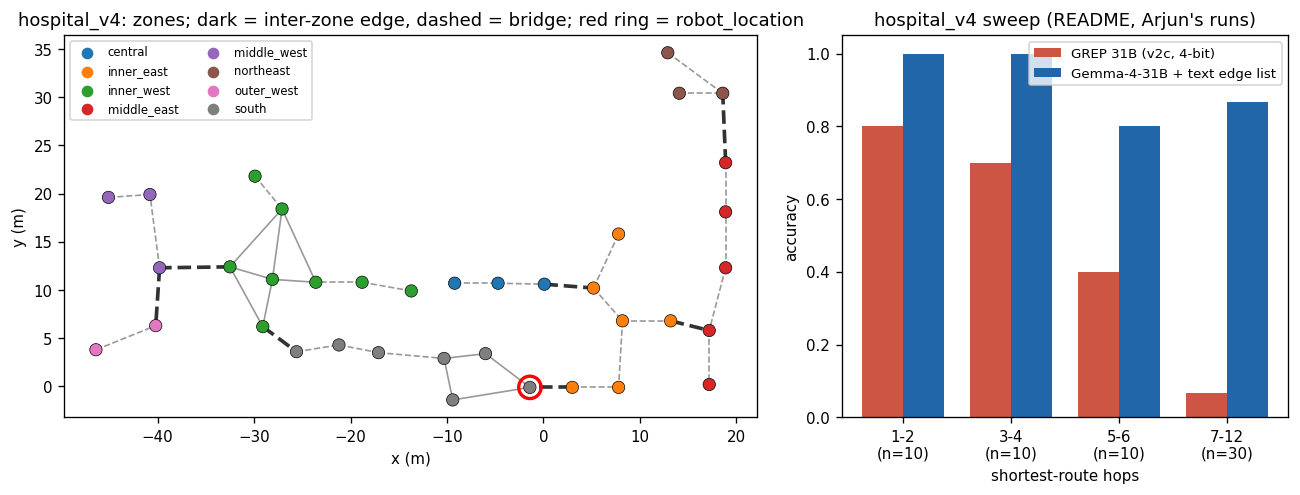

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
pos = {r["name"]: tuple(r["coords"]) for r in d4["graph"]["regions"]}
cmap = plt.get_cmap("tab10"); zcol = {z: cmap(i) for i, z in enumerate(zones)}
bridges = set(map(tuple, map(sorted, nx.bridges(G4))))
for u, v in G4.edges:
    is_inter = zone[u] != zone[v]
    ax.plot(*zip(pos[u], pos[v]), color="#333" if is_inter else "#999", lw=2.2 if is_inter else 1.0,
            ls="--" if tuple(sorted((u, v))) in bridges else "-", zorder=1)
ax.scatter(*zip(*[pos[n] for n in G4]), c=[zcol[zone[n]] for n in G4], s=55, zorder=2, edgecolor="k", lw=0.4)
rl = d4["graph"]["robot_location"]; ax.scatter(*pos[rl], s=180, facecolor="none", edgecolor="red", lw=2, zorder=3)
for z in zones: ax.scatter([], [], c=[zcol[z]], label=z)
ax.legend(fontsize=7, loc="upper left", ncol=2); ax.set_aspect("equal"); ax.set_title("hospital_v4: zones; dark = inter-zone edge, dashed = bridge; red ring = robot_location")
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

ax = axes[1]
# README table (Arjun, 2026-10-16/23): sweep buckets, GREP 31B 4-bit / unquantized, Gemma text edges
buckets = ["1-2", "3-4", "5-6", "7-12"]; n_b = [10, 10, 10, 30]
grep_4bit = [8, 7, 4, 2]; text_edges = [10, 10, 8, 26]
x = np.arange(len(buckets)); w = 0.38
ax.bar(x - w / 2, np.array(grep_4bit) / n_b, w, color="#cc5544", label="GREP 31B (v2c, 4-bit)")
ax.bar(x + w / 2, np.array(text_edges) / n_b, w, color="#2266aa", label="Gemma-4-31B + text edge list")
ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(buckets, n_b)]); ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy"); ax.set_xlabel("shortest-route hops"); ax.legend(fontsize=8)
ax.set_title("hospital_v4 sweep (README, Arjun's runs)")
fig.tight_layout(); fig.savefig(f"{FIGS}/hospital_graphs_layout_results.png")

## 8. Can a sparse community generator reproduce these statistics?

Quick check of the candidate layout from the e22 discussion: each community is a random
spanning tree plus `extra` edges, communities joined by `bridges` edges along a grid /
ring / chain. Compared against hospital_v4's degree, dead-end fraction, bridge fraction,
cycles-per-region and diameter, and against the current SBM generator at its n60 and n100
settings. This is a design probe, not a corpus: the real generator lives in
`scripts/generate_eval_graphs.py` and does not have these layouts yet.

In [9]:
import random

def building(nc, npc, extra, bridges, layout, seed):
    rng = random.Random(seed); G = nx.Graph(); comms = []
    for c in range(nc):
        nodes = [c * npc + i for i in range(npc)]; comms.append(nodes)
        T = nx.random_labeled_tree(npc, seed=rng.randrange(1 << 30))
        G.add_edges_from((nodes[u], nodes[v]) for u, v in T.edges)
        cand = [(a, b) for i, a in enumerate(nodes) for b in nodes[i + 1:] if not G.has_edge(a, b)]
        for a, b in rng.sample(cand, min(extra, len(cand))): G.add_edge(a, b)
    if layout == "grid":
        w = int(np.ceil(np.sqrt(nc))); pairs = []
        for c in range(nc):
            if (c + 1) % w and c + 1 < nc: pairs.append((c, c + 1))
            if c + w < nc: pairs.append((c, c + w))
    else:
        pairs = [(c, c + 1) for c in range(nc - 1)] + ([(nc - 1, 0)] if layout == "ring" else [])
    for a, b in pairs:
        for _ in range(bridges): G.add_edge(rng.choice(comms[a]), rng.choice(comms[b]))
    return G

def sbm(nc, npc, p_in, p_out, seed):
    prob = np.full((nc, nc), p_out); np.fill_diagonal(prob, p_in)
    for s in range(seed, seed + 50):
        G = nx.stochastic_block_model([npc] * nc, prob.tolist(), seed=s)
        if nx.is_connected(G): return G
    raise RuntimeError

def summarize(gen, n=25):
    st = pd.DataFrame([graph_stats({"graph": {"objects": []}}, gen(s)) for s in range(n)])
    return st[["regions", "region_edges", "mean_deg", "deg1_frac", "bridge_frac", "cycles", "diameter", "aspl"]].mean()

cands = {
    "hospital_v4 (target)": pd.Series(graph_stats(*hosp["hospital_v4"]))[["regions", "region_edges", "mean_deg", "deg1_frac", "bridge_frac", "cycles", "diameter", "aspl"]],
    "SBM 6x8 p.6/.05 (current n60)": summarize(lambda s: sbm(6, 8, 0.6, 0.05, s)),
    "SBM 12x8 p.6/.05 (naive n100)": summarize(lambda s: sbm(12, 8, 0.6, 0.05, s)),
    "grid 16x6 extra1 br1": summarize(lambda s: building(16, 6, 1, 1, "grid", s)),
    "grid 20x5 extra1 br1": summarize(lambda s: building(20, 5, 1, 1, "grid", s)),
    "grid 12x8 extra1 br1": summarize(lambda s: building(12, 8, 1, 1, "grid", s)),
    "ring 12x8 extra2 br2": summarize(lambda s: building(12, 8, 2, 2, "ring", s)),
    "chain 8x5 extra0 br1 (v4-sized)": summarize(lambda s: building(8, 5, 0, 1, "chain", s)),
    "grid 8x5 extra0 br1 (v4-sized)": summarize(lambda s: building(8, 5, 0, 1, "grid", s)),
}
cmp = pd.DataFrame(cands).T
cmp["cycles/region"] = cmp["cycles"] / cmp["regions"]
cmp.round(2)

,regions,region_edges,mean_deg,deg1_frac,bridge_frac,cycles,diameter,aspl,cycles/region
hospital_v4 (target),37.0,40.00,2.16,0.24,0.72,4.00,20.00,8.36,0.11
SBM 6x8 p.6/.05 (current n60),48.0,150.76,6.28,0.00,0.00,103.76,4.40,2.43,2.16
SBM 12x8 p.6/.05 (naive n100),96.0,409.96,8.54,0.00,0.00,314.96,4.12,2.41,3.28
grid 16x6 extra1 br1,96.0,120.00,2.50,0.17,0.16,25.00,16.28,6.92,0.26
grid 20x5 extra1 br1,100.0,131.00,2.62,0.13,0.11,32.00,16.36,6.80,0.32
grid 12x8 extra1 br1,96.0,113.00,2.35,0.23,0.26,18.00,16.72,7.30,0.19
ring 12x8 extra2 br2,96.0,131.88,2.75,0.13,0.11,36.88,16.76,7.70,0.38
chain 8x5 extra0 br1 (v4-sized),40.0,39.00,1.95,0.33,1.00,0.00,22.92,8.72,0.00
grid 8x5 extra0 br1 (v4-sized),40.0,42.00,2.10,0.29,0.39,3.00,12.12,5.34,0.08


## 8b. Spatial generators vs hospital_v4

Section 8 showed that "sparse communities on a grid" can hit the target. Here the natural
family for a floor plan — spatial graphs — is compared at N=40 (hospital size) and N=100
(e22 target): random geometric graph at its connectivity radius, symmetrised kNN, Delaunay
and its Gabriel / relative-neighbourhood subgraphs, Euclidean MST plus a fraction of
Delaunay edges, and a BSP floor plan (recursive rectangle split into rooms, adjacency =
shared wall, doors = random spanning tree of walls + `door_extra` of the other walls).
20 seeds each. The table is saved to `../docs/hospital_graphs_generator_candidates.csv`
and feeds the e22 design note.

In [10]:
import random
from scipy.spatial import Delaunay

def gen_stats(G):
    d = np.array([x for _, x in G.degree()])
    return dict(N=G.number_of_nodes(), E=G.number_of_edges(), deg=d.mean(), dead=np.mean(d == 1),
                bridge=len(list(nx.bridges(G))) / G.number_of_edges(), cyc_per_n=(G.number_of_edges() - G.number_of_nodes() + 1) / G.number_of_nodes(),
                diam=nx.diameter(G), aspl=nx.average_shortest_path_length(G), clust=nx.average_clustering(G))

def connect(G, pos):
    while not nx.is_connected(G):
        comps = list(nx.connected_components(G)); a = comps[0]; rest = set(G) - a
        G.add_edge(*min(((u, v) for u in a for v in rest), key=lambda e: np.linalg.norm(pos[e[0]] - pos[e[1]])))
    return G

def rgg(N, seed):
    pos = np.random.default_rng(seed).random((N, 2)); r = np.sqrt(np.log(N) / (np.pi * N)) * 1.1
    return connect(nx.random_geometric_graph(N, r, pos={i: pos[i] for i in range(N)}, seed=seed), pos)

def knn(N, k, seed):
    pos = np.random.default_rng(seed).random((N, 2)); G = nx.Graph(); G.add_nodes_from(range(N))
    D = np.linalg.norm(pos[:, None] - pos[None], axis=-1)
    for i in range(N):
        for j in np.argsort(D[i])[1:k + 1]: G.add_edge(i, int(j))
    return connect(G, pos)

def delaunay_family(N, seed, kind):
    pos = np.random.default_rng(seed).random((N, 2)); tri = Delaunay(pos); G = nx.Graph(); G.add_nodes_from(range(N))
    for s in tri.simplices:
        for a in range(3):
            for b in range(a + 1, 3): G.add_edge(int(s[a]), int(s[b]))
    if kind == "delaunay": return G, pos
    D = np.linalg.norm(pos[:, None] - pos[None], axis=-1); H = nx.Graph(); H.add_nodes_from(range(N))
    for u, v in G.edges:
        d = D[u, v]
        if kind == "gabriel":
            m = (pos[u] + pos[v]) / 2; ok = all(np.linalg.norm(pos[w] - m) >= d / 2 - 1e-12 for w in range(N) if w not in (u, v))
        else:
            ok = all(max(D[u, w], D[v, w]) >= d for w in range(N) if w not in (u, v))
        if ok: H.add_edge(u, v)
    return H, pos

def mst_plus(N, extra_frac, seed):
    rng = random.Random(seed); G, P = delaunay_family(N, seed, "delaunay")
    for u, v in G.edges: G[u][v]["w"] = np.linalg.norm(P[u] - P[v])
    H = nx.Graph(nx.minimum_spanning_tree(G, weight="w")); others = [e for e in G.edges if not H.has_edge(*e)]
    H.add_edges_from(rng.sample(others, int(extra_frac * len(others)))); return H

def bsp_floorplan(N, door_extra, seed, min_aspect=0.35):
    rng = random.Random(seed); rooms = [(0.0, 0.0, 1.0, 0.7)]
    while len(rooms) < N:
        i = max(range(len(rooms)), key=lambda j: rooms[j][2] * rooms[j][3]); x, y, w, h = rooms.pop(i)
        f = rng.uniform(0.35, 0.65)
        if w / h > 1 / min_aspect or (w >= h and rng.random() < 0.8): rooms += [(x, y, w * f, h), (x + w * f, y, w * (1 - f), h)]
        else: rooms += [(x, y, w, h * f), (x, y + h * f, w, h * (1 - f))]
    def shared(a, b):
        ax, ay, aw, ah = a; bx, by, bw, bh = b; eps = 1e-9
        if abs(ax + aw - bx) < eps or abs(bx + bw - ax) < eps: return min(ay + ah, by + bh) - max(ay, by) > 0.02
        if abs(ay + ah - by) < eps or abs(by + bh - ay) < eps: return min(ax + aw, bx + bw) - max(ax, bx) > 0.02
        return False
    W = nx.Graph([(i, j) for i in range(len(rooms)) for j in range(i + 1, len(rooms)) if shared(rooms[i], rooms[j])])
    for u, v in W.edges: W[u][v]["w"] = rng.random()
    G = nx.Graph(nx.minimum_spanning_tree(W, weight="w")); G.add_nodes_from(range(len(rooms)))
    others = [e for e in W.edges if not G.has_edge(*e)]; G.add_edges_from(rng.sample(others, int(door_extra * len(others)))); return G

def run(name, gen, n=20):
    return pd.DataFrame([gen_stats(gen(s)) for s in range(n)]).mean().rename(name)

geo_rows = [pd.Series(dict(N=37, E=40, deg=2.16, dead=0.24, bridge=0.72, cyc_per_n=0.11, diam=20, aspl=8.36, clust=0.05), name="hospital_v4 (target)")]
for N in (40, 100):
    geo_rows += [run(f"SBM 6x8-style p.6/.05 N={N}", lambda s: sbm(max(2, N // 8), 8, 0.6, 0.05, s)),
                 run(f"RGG conn-radius N={N}", lambda s: rgg(N, s)),
                 run(f"kNN k=2 sym N={N}", lambda s: knn(N, 2, s)),
                 run(f"kNN k=3 sym N={N}", lambda s: knn(N, 3, s)),
                 run(f"Delaunay N={N}", lambda s: delaunay_family(N, s, "delaunay")[0]),
                 run(f"Gabriel N={N}", lambda s: delaunay_family(N, s, "gabriel")[0]),
                 run(f"RNG N={N}", lambda s: delaunay_family(N, s, "rng")[0]),
                 run(f"EMST+5% N={N}", lambda s: mst_plus(N, 0.05, s)),
                 run(f"EMST+15% N={N}", lambda s: mst_plus(N, 0.15, s)),
                 run(f"BSP floorplan doors+5% N={N}", lambda s: bsp_floorplan(N, 0.05, s)),
                 run(f"BSP floorplan doors+15% N={N}", lambda s: bsp_floorplan(N, 0.15, s)),
                 run(f"BSP floorplan doors+30% N={N}", lambda s: bsp_floorplan(N, 0.30, s))]
geo = pd.DataFrame(geo_rows); geo.index.name = "model"
geo.round(3).to_csv(f"{FIGS}/hospital_graphs_generator_candidates.csv")
geo.round(2)

,N,E,deg,dead,bridge,cyc_per_n,diam,aspl,clust
model,,,,,,,,,
hospital_v4 (target),37.0,40.00,2.16,0.24,0.72,0.11,20.00,8.36,0.05
SBM 6x8-style p.6/.05 N=40,40.0,118.45,5.92,0.00,0.00,1.99,4.60,2.41,0.37
RGG conn-radius N=40,40.0,79.45,3.97,0.08,0.13,1.01,13.15,5.35,0.54
kNN k=2 sym N=40,40.0,55.05,2.75,0.00,0.18,0.40,15.85,6.67,0.49
kNN k=3 sym N=40,40.0,76.35,3.82,0.00,0.02,0.93,11.00,4.95,0.59
Delaunay N=40,40.0,107.85,5.39,0.00,0.00,1.72,5.80,2.87,0.47
Gabriel N=40,40.0,64.65,3.23,0.04,0.03,0.64,9.60,4.22,0.22
RNG N=40,40.0,44.10,2.20,0.14,0.23,0.13,13.45,5.82,0.00
EMST+5% N=40,40.0,42.00,2.10,0.22,0.62,0.07,18.10,7.40,0.03


## 9. Findings

Three distribution shifts separate hospital_v4 from the graphs GREP trained on. The hop
shift that Arjun named is the visible one; the other two are its cause and a second,
independent gap.

1. **Density (the cause of the hop shift).** hospital_v4 regions have 2.16 neighbours
   (24% dead ends, 72% of edges are bridges, 4 cycles in 37 regions); n60_v3 regions have
   6.25 (0.1% dead ends, 0 bridges, ~103 cycles in 48 regions). Diameter 20 vs 4.5. The
   SBM generator cannot reach this by adding communities: 12×8 at p=0.6/0.05 gives
   diameter 4.1 (section 8). Inside hospital zones the edge density is 0.33–0.67 of a
   clique only because zones are tiny (2–8 regions); zones are joined by exactly one
   doorway edge each (7 inter-zone edges, a tree over 8 zones).
2. **Route length (the symptom).** 64% of hospital_v4 region pairs and 58% of the sweep
   tasks are ≥6 hops; the v2c training routes have 1.1% ≥6 hops and none ≥8. The sweep's
   7–12-hop bucket, where GREP scores 2/30, has zero training support.
3. **Start grounding.** 58 of the 60 sweep tasks start at a *named* region that is not
   `robot_location` (plaza_1), and only 3% say "starting area". In every GREP training
   corpus 100% of routes start at `robot_location`, so "start = robot_location" was always
   a valid shortcut (e21 analysis). The n60 eval has 82% robot_location starts. The sweep
   therefore also tests text→node start grounding the model never had to learn. The 10
   main v4 tasks (80% robot_location starts) are closer to training on this axis.

Smaller differences: names are `<zone>_<kind>_<k>` with up to 6 siblings of one type
(`inner_west_hall_1..6`) and 20 regions of kind "hall", against ≤3 siblings in training —
the ordinal-sibling error class from n60 gets more room; the hospital has 14 objects
(1 per category) vs ~15 in training, so objects are not a gap; the sweep tasks are 100%
object-goal and have no via/avoid constraints, while n60 eval tasks are 32% via and
29% avoid.

**What the generator must match (section 8):** mean degree 2.1–2.6, dead-end fraction
0.15–0.25, bridge fraction ≥0.1 (SBM: 0), ~0.1–0.3 cycles per region, diameter ≥15 at
~100 regions so 6–7-hop pairs are the mode and 12–15-hop pairs exist. The grid /
ring-of-sparse-communities layouts land in that range; `grid 8x5 extra0 br1` reproduces
hospital_v4's size, degree, dead ends and cycles at 40 regions (diameter 12 vs 20 — the
hospital is more chain-like than a grid, so a chain/grid mix is needed).

In [11]:
# Pair-hop mass by bucket, for the summary table
def bucket(a):
    a = np.asarray(a); return {"1-2": np.mean(a <= 2), "3-5": np.mean((a >= 3) & (a <= 5)), "6-7": np.mean((a >= 6) & (a <= 7)),
                               "8-12": np.mean((a >= 8) & (a <= 12)), ">=13": np.mean(a >= 13)}
pd.DataFrame({"n60_v3 region pairs": bucket(ph_n60), "v2c training routes": bucket(v2c_hops),
              "hospital_v4 region pairs": bucket(ph_v4), "hospital_v4 sweep tasks": bucket(sweep_hops)}).T.round(3)

,1-2,3-5,6-7,8-12,>=13
n60_v3 region pairs,0.516,0.484,0.000,0.000,0.000
v2c training routes,0.078,0.910,0.011,0.000,0.000
hospital_v4 region pairs,0.132,0.230,0.135,0.248,0.255
hospital_v4 sweep tasks,0.167,0.250,0.167,0.417,0.000
